# 04. EDA исходного набора изображений — Open Images V7, класс Car

| Параметр | Значение |
|---|---|
| Набор данных | Open Images V7, задача `detections`, класс `Car` (`/m/0k4j`) |
| Модальность | изображения, ограничивающие рамки (bounding boxes) |
| Задача | обнаружение объектов (object detection), один класс |
| Лицензия аннотаций | CC BY 4.0 |
| Лицензия изображений | по файлу; в проверенной части — CC BY 2.0 (см. раздел 7) |
| Источник | https://storage.googleapis.com/openimages/web/download_v7.html |
| Дата обращения | 22.10.2026 |
| Ноутбук | версия 1.0 от 22.10.2026 |
| Исполнители | Якунченков К. А., Графов Г. П. |

**Назначение.** Зафиксировать характеристики исходного набора аннотаций до обогащения:
объём и структуру, геометрию рамок, распределение атрибутов, лицензионную и авторскую
структуру, и построить детерминированную схему формирования подвыборки.

**Принятое проектное решение.** Подвыборка формируется из раздела `validation`
(41 620 изображений, из них 5 095 содержат класс Car). Причины: (1) требование ТЗ
«не менее 3 000 экземпляров» выполняется с запасом; (2) все три части — train,
validation, test — берутся из одного раздела, что исключает пересечение идентификаторов
и разницу в политике аннотирования между разделами; (3) файл аннотаций обучения
занимает около 1,2 ГБ и недоступен для быстрой воспроизводимой сборки.

**Выходные артефакты** (сохраняются в `reports/`):

* `tables/cars_dataset_passport.csv` — паспорт файлов и контрольные суммы;
* `tables/cars_annotation_stats.csv` — объём и структура аннотаций;
* `tables/cars_box_geometry.csv` — статистика геометрии рамок;
* `tables/cars_attributes.csv` — распределение атрибутов;
* `tables/cars_license_author.csv` — лицензии, домены первоисточника, авторы;
* `tables/cars_subset_plan.csv` — план подвыборки (train / val / test);
* `tables/cars_pilot_design.csv`, `tables/cars_pilot_strata.csv`,
  `manifests/cars_pilot_sample.csv` — план пилотной разметки (раздел 9);
* `tables/cars_size_eval.csv`, `tables/cars_negatives_plan.csv` — оценивание по размерным
  группам и отрицательные примеры (раздел 10);
* `tables/cars_author_ess.csv` — эффективный объём выборки (раздел 11);
* `tables/cars_results_template.csv` — регламент и таблица результатов (раздел 12);
* `manifests/cars_val_manifest.csv` — реестр изображений подвыборки
  (`image_id`, `split`, `author`, `license`, `original_url`, `landing_url`);
* `figures/11_cars_boxes_per_image.png`, `12_cars_area_dist.png`,
  `13_cars_attributes.png`, `14_cars_position.png`, `16_cars_pilot_strata.png`, `15_cars_author_concentration.png`.

**Требования воспроизводимости.** Фиксированный `RANDOM_STATE`, контрольные суммы
входных CSV, детерминированная схема разбиения (см. раздел 8).

## 0. Окружение, импорты и константы

In [1]:
# В Google Colab все зависимости установлены. Локально при первом запуске:
# %pip install -q pandas numpy matplotlib

import hashlib
import platform
import sys
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("Python :", platform.python_version())
for m in (np, pd, plt.matplotlib):
    print(f"{m.__name__:11s}:", m.__version__)

Python : 3.13.16
numpy      : 2.3.5
pandas     : 2.2.3
matplotlib : 3.10.9


In [2]:
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    ROOT = Path("/content/frame203")
else:
    ROOT = Path.cwd()
    if ROOT.name == "notebooks":
        ROOT = ROOT.parent

DATA_DIR = ROOT / "data" / "raw" / "openimages"
REPORTS = ROOT / "reports"
TABLES = REPORTS / "tables"
FIGURES = REPORTS / "figures"
MANIFESTS = REPORTS / "manifests"
for p in (DATA_DIR, TABLES, FIGURES, MANIFESTS):
    p.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
ACCESS_DATE = "2026-10-22"
CAR_LABEL = "/m/0k4j"          # Car в таксономии Open Images

FILES = {
    "val_bbox": ("validation-annotations-bbox.csv",
                 "https://storage.googleapis.com/openimages/v5/validation-annotations-bbox.csv",
                 None),
    "class_desc": ("class-descriptions-boxable.csv",
                   "https://storage.googleapis.com/openimages/v5/class-descriptions-boxable.csv",
                   None),
    "val_images": ("validation-images-with-rotation.csv",
                   "https://storage.googleapis.com/openimages/2018_04/validation/validation-images-with-rotation.csv",
                   None),
}

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
print("ROOT   :", ROOT)
print("Данные :", DATA_DIR)

ROOT   : /tmp/run203
Данные : /tmp/run203/data/raw/openimages


## 1. Загрузка аннотаций и контроль целостности

Файлы аннотаций Open Images не меняются в рамках версии набора, поэтому контрольная
сумма фиксирует версию таксономии и разметки, с которой работают оба участника.

In [3]:
def sha256(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def ensure_file(key: str) -> Path:
    name, url, _ = FILES[key]
    path = DATA_DIR / name
    if not path.exists():
        print("Скачивание:", url)
        urllib.request.urlretrieve(url, path)
    print(f"{name}: {path.stat().st_size / 1e6:.1f} МБ, SHA-256 {sha256(path)[:16]}…")
    return path


paths = {k: ensure_file(k) for k in FILES}

bbox = pd.read_csv(paths["val_bbox"])
classes = pd.read_csv(paths["class_desc"], header=None, names=["label_id", "label_name"])
images = pd.read_csv(paths["val_images"])

passport = pd.DataFrame(
    [
        ("источник", "Open Images V7, validation"),
        ("файл аннотаций", paths["val_bbox"].name),
        ("SHA-256 аннотаций", sha256(paths["val_bbox"])),
        ("SHA-256 метаданных изображений", sha256(paths["val_images"])),
        ("строк в файле аннотаций", len(bbox)),
        ("строк в метаданных изображений", len(images)),
        ("дата обращения", ACCESS_DATE),
    ],
    columns=["показатель", "значение"],
)
display(passport)
passport.to_csv(TABLES / "cars_dataset_passport.csv", index=False)
print("\nКласс Car в таксономии:", classes.loc[classes.label_id == CAR_LABEL, "label_name"].item())

validation-annotations-bbox.csv: 25.1 МБ, SHA-256 d8bbd59410af1483…
class-descriptions-boxable.csv: 0.0 МБ, SHA-256 2fa47fb1b87e71c9…
validation-images-with-rotation.csv: 15.2 МБ, SHA-256 ed93a0e121fe345e…


,показатель,значение
0,источник,"Open Images V7, validation"
1,файл аннотаций,validation-annotations-bbox.csv
2,SHA-256 аннотаций,d8bbd59410af14835d7733165a7bb8a3f0213981b22dd5...
3,SHA-256 метаданных изображений,ed93a0e121fe345effdfc7359b848dbc64a1ff6778c8c7...
4,строк в файле аннотаций,303980
5,строк в метаданных изображений,41620
6,дата обращения,2026-10-22



Класс Car в таксономии: Car


## 2. Схема аннотаций и валидация

Проверяются: диапазон координат, порядок границ рамки, ненулевая площадь, дубликаты
рамок, согласованность идентификаторов с метаданными изображений, значения атрибутов.

In [4]:
attr_cols = ["IsOccluded", "IsTruncated", "IsGroupOf", "IsDepiction", "IsInside"]

checks = {
    "всего рамок в validation": len(bbox),
    "рамок класса Car": int((bbox.LabelName == CAR_LABEL).sum()),
    "уникальных классов в validation": bbox.LabelName.nunique(),
    "координаты вне [0, 1]": int(((bbox[["XMin", "XMax", "YMin", "YMax"]] < 0) |
                                  (bbox[["XMin", "XMax", "YMin", "YMax"]] > 1)).any(axis=1).sum()),
    "нарушено XMin < XMax": int((bbox.XMin >= bbox.XMax).sum()),
    "нарушено YMin < YMax": int((bbox.YMin >= bbox.YMax).sum()),
    "значения атрибутов вне {0, 1}": int((~bbox[attr_cols].isin([0, 1])).any(axis=1).sum()),
    "уровни Confidence": ", ".join(f"{k}" for k in sorted(bbox.Confidence.unique())),
    "рамок с Confidence < 1": int((bbox.Confidence < 1).sum()),
}

car = bbox[bbox.LabelName == CAR_LABEL].copy()
car_dups = int(car.duplicated(subset=["ImageID", "XMin", "XMax", "YMin", "YMax"]).sum())
checks["дубликатов рамок внутри Car"] = car_dups
checks["изображений с Car"] = car.ImageID.nunique()
checks["изображений с Car без метаданных"] = int((~car.ImageID.isin(images.ImageID)).sum())

for k, v in checks.items():
    print(f"{k:44s}: {v}")

всего рамок в validation                    : 303980
рамок класса Car                            : 9924
уникальных классов в validation             : 570
координаты вне [0, 1]                       : 0
нарушено XMin < XMax                        : 0
нарушено YMin < YMax                        : 0
значения атрибутов вне {0, 1}               : 0
уровни Confidence                           : 1
рамок с Confidence < 1                      : 0
дубликатов рамок внутри Car                 : 0
изображений с Car                           : 5095
изображений с Car без метаданных            : 0


## 3. Объём и структура аннотаций

Плотность объектов определяет как сложность задачи, так и стратегию аугментации:
при медиане 1 объекта на изображение Mosaic и Copy-Paste дают основной прирост.

,показатель,значение
0,рамок Car,9924.000
1,изображений с Car,5095.000
2,"рамок на изображение, среднее",1.948
3,"рамок на изображение, медиана",1.000
4,"рамок на изображение, максимум",43.000
5,изображений с одной рамкой,2939.000
6,"доля изображений с одной рамкой, %",57.700
7,изображений с >= 5 рамками,343.000
8,изображений с >= 10 рамками,26.000
9,"доля раздела validation с Car, %",12.240


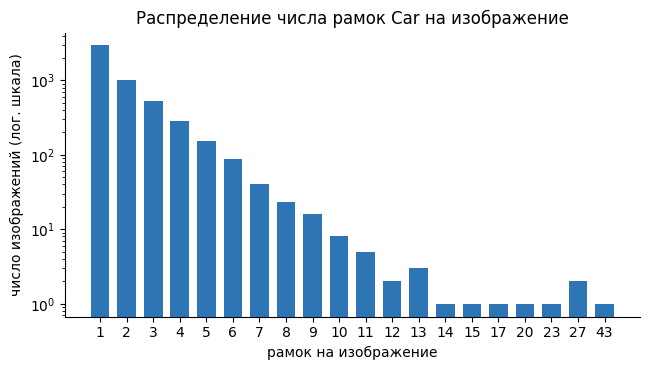

In [5]:
per_image = car.groupby("ImageID").size()
n_boxes = len(car)
n_images = car.ImageID.nunique()

stats = pd.DataFrame(
    [
        ("рамок Car", n_boxes),
        ("изображений с Car", n_images),
        ("рамок на изображение, среднее", round(per_image.mean(), 3)),
        ("рамок на изображение, медиана", int(per_image.median())),
        ("рамок на изображение, максимум", int(per_image.max())),
        ("изображений с одной рамкой", int((per_image == 1).sum())),
        ("доля изображений с одной рамкой, %", round((per_image == 1).mean() * 100, 1)),
        ("изображений с >= 5 рамками", int((per_image >= 5).sum())),
        ("изображений с >= 10 рамками", int((per_image >= 10).sum())),
        ("доля раздела validation с Car, %", round(n_images / len(images) * 100, 2)),
    ],
    columns=["показатель", "значение"],
)
display(stats)
stats.to_csv(TABLES / "cars_annotation_stats.csv", index=False)

fig, ax = plt.subplots(figsize=(6.6, 3.8))
vc = per_image.value_counts().sort_index()
ax.bar(vc.index.astype(str), vc.values, color="#2E75B6", width=0.7)
ax.set_yscale("log")
ax.set_title("Распределение числа рамок Car на изображение")
ax.set_xlabel("рамок на изображение")
ax.set_ylabel("число изображений (лог. шкала)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "11_cars_boxes_per_image.png", dpi=160)
plt.show()

## 4. Геометрия рамок

Площадь нормирована на площадь кадра: это позволяет сопоставлять объекты разных
разрешений. Пороги COCO (`small < 32²`, `medium 32²–96²`, `large > 96²` пикселей)
здесь не применимы напрямую — размеры изображений различаются, поэтому используется
доля площади кадра, а классы размеров задаются по ней.

,показатель,min,5%,25%,50%,75%,95%,max
area,"площадь, доля кадра",0.000,0.002,0.016,0.159,0.563,0.899,1.000
w,"ширина, доля кадра",0.004,0.039,0.128,0.449,0.861,1.000,1.000
h,"высота, доля кадра",0.007,0.036,0.123,0.381,0.673,0.956,1.000
aspect,отношение сторон,0.055,0.410,0.922,1.162,1.543,2.461,18.975
cx,центр по X,0.006,0.062,0.388,0.500,0.600,0.936,0.995
cy,центр по Y,0.009,0.116,0.323,0.481,0.544,0.684,0.991


,рамок,"доля, %"
area,,
"< 0,5 %",1257,12.67
"0,5–2 %",1469,14.80
2–5 %,1092,11.00
5–15 %,1079,10.87
15–40 %,1327,13.37
> 40 %,3700,37.28


Медианная площадь: 15.93% кадра; доля рамок меньше 0,5 % кадра: 12.67%


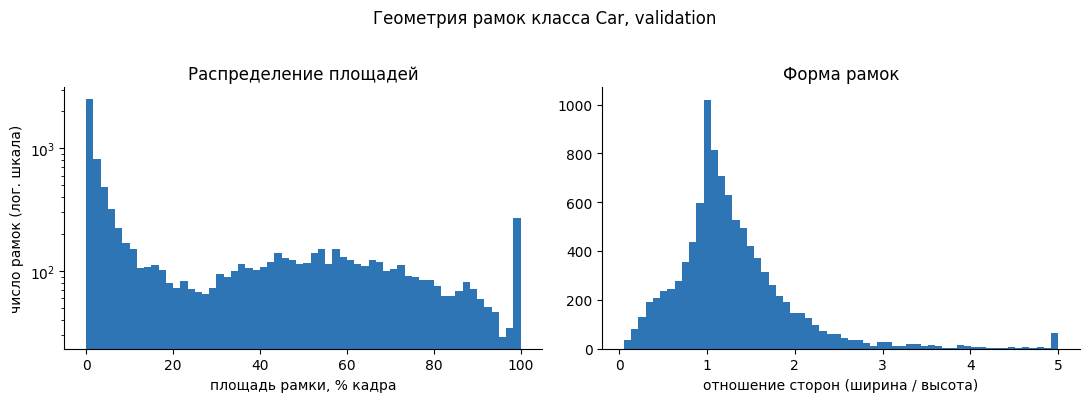

In [6]:
car["w"] = car.XMax - car.XMin
car["h"] = car.YMax - car.YMin
car["area"] = car.w * car.h
car["aspect"] = car.w / car.h
car["cx"] = (car.XMin + car.XMax) / 2
car["cy"] = (car.YMin + car.YMax) / 2

geo = car[["area", "w", "h", "aspect", "cx", "cy"]].describe(
    percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T.round(3)
geo["показатель"] = ["площадь, доля кадра", "ширина, доля кадра", "высота, доля кадра",
                     "отношение сторон", "центр по X", "центр по Y"]
display(geo[["показатель", "min", "5%", "25%", "50%", "75%", "95%", "max"]])
geo.to_csv(TABLES / "cars_box_geometry.csv")

bins = [0, 0.005, 0.02, 0.05, 0.15, 0.40, 1.01]
labels = ["< 0,5 %", "0,5–2 %", "2–5 %", "5–15 %", "15–40 %", "> 40 %"]
size_bins = pd.cut(car.area, bins=bins, labels=labels, right=False).value_counts().reindex(labels)
size_table = pd.DataFrame({"рамок": size_bins,
                           "доля, %": (size_bins / len(car) * 100).round(2)})
display(size_table)
print(f"Медианная площадь: {car.area.median():.2%} кадра; "
      f"доля рамок меньше 0,5 % кадра: {(car.area < 0.005).mean():.2%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
axes[0].hist(car.area * 100, bins=60, color="#2E75B6")
axes[0].set_yscale("log")
axes[0].set_xlabel("площадь рамки, % кадра")
axes[0].set_ylabel("число рамок (лог. шкала)")
axes[0].set_title("Распределение площадей")
axes[1].hist(car.aspect.clip(0, 5), bins=60, color="#2E75B6")
axes[1].set_xlabel("отношение сторон (ширина / высота)")
axes[1].set_title("Форма рамок")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Геометрия рамок класса Car, validation", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES / "12_cars_area_dist.png", dpi=160, bbox_inches="tight")
plt.show()

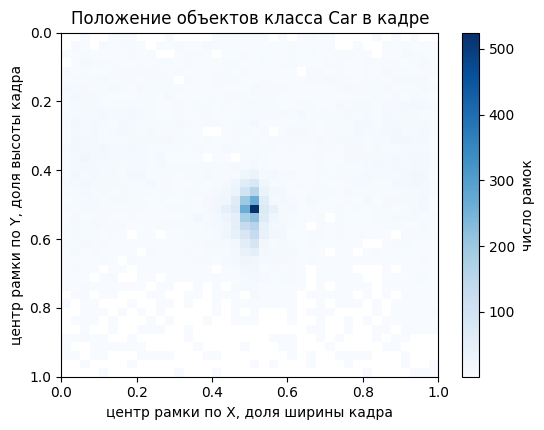

Доля рамок с центром в центральной половине кадра: 55.5%
Следствие: обрезка краёв кадра при аугментации удаляет объекты, поэтому для части кадров применяется только геометрическое искажение.


In [7]:
# Положение объектов в кадре: важно для аугментации и для выбора стратегии тайлинга
fig, ax = plt.subplots(figsize=(5.6, 4.4))
h = ax.hist2d(car.cx, car.cy, bins=40, range=[[0, 1], [0, 1]], cmap="Blues", cmin=1)
fig.colorbar(h[3], ax=ax, label="число рамок")
ax.set_xlabel("центр рамки по X, доля ширины кадра")
ax.set_ylabel("центр рамки по Y, доля высоты кадра")
ax.invert_yaxis()          # начало координат изображения — левый верхний угол
ax.set_title("Положение объектов класса Car в кадре")
fig.tight_layout()
fig.savefig(FIGURES / "14_cars_position.png", dpi=160)
plt.show()

share_center = float(((car.cx.between(0.25, 0.75)) & (car.cy.between(0.25, 0.75))).mean())
print(f"Доля рамок с центром в центральной половине кадра: {share_center:.1%}")
print("Следствие: обрезка краёв кадра при аугментации удаляет объекты, "
      "поэтому для части кадров применяется только геометрическое искажение.")

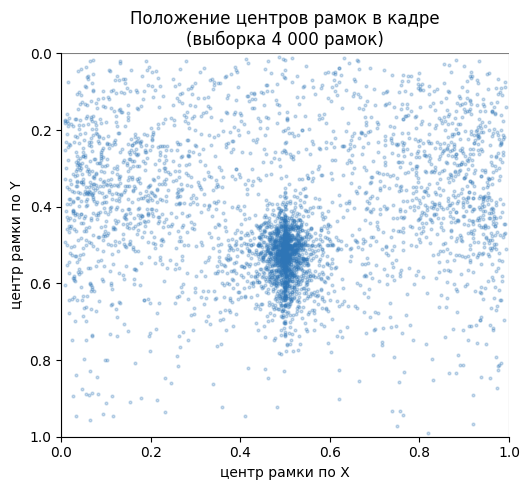

In [8]:
fig, ax = plt.subplots(figsize=(5.4, 5.0))
sample = car.sample(min(4000, len(car)), random_state=RANDOM_STATE)
ax.scatter(sample.cx, sample.cy, s=4, alpha=0.25, color="#2E75B6")
ax.plot([0, 1, 1, 0, 0], [0, 0, 1, 1, 0], color="grey", linewidth=0.8)
ax.set_xlim(0, 1)
ax.set_ylim(1, 0)
ax.set_xlabel("центр рамки по X")
ax.set_ylabel("центр рамки по Y")
ax.set_title("Положение центров рамок в кадре\n(выборка 4 000 рамок)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "14_cars_position.png", dpi=160)
plt.show()

## 5. Атрибуты объектов

Атрибуты Open Images (`IsOccluded`, `IsTruncated`, `IsGroupOf`, `IsDepiction`,
`IsInside`) переносятся в codebook ручной разметки без изменения определений: это
условие сопоставимости ручных рамок с исходными.

,атрибут,рамок с атрибутом,"доля, %"
0,IsOccluded,3618,36.46
1,IsTruncated,3110,31.34
2,IsGroupOf,682,6.87
3,IsDepiction,102,1.03
4,IsInside,157,1.58
5,без атрибутов (чистый объект),4103,41.34
6,occluded и truncated одновременно,1446,14.57


/tmp/ipykernel_2099/490260531.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(plot_df["атрибут"], rotation=14, ha="right")


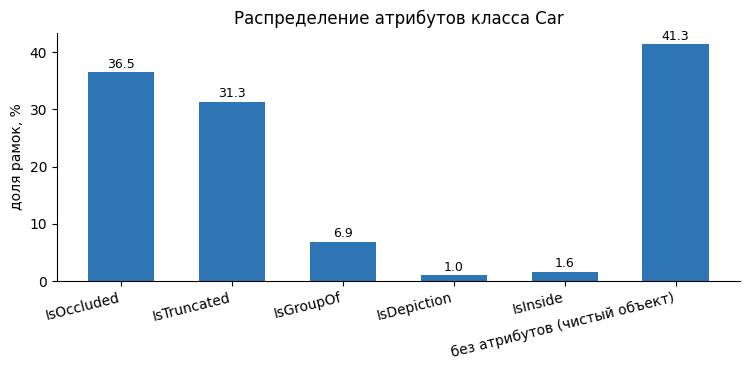

Следствия для codebook: доля перекрытых и обрезанных объектов задаёт ожидаемую структуру ручного набора; расхождение более чем на 10 п.п. означает сдвиг домена.


In [9]:
attr_rows = []
for c in attr_cols:
    n = int(car[c].sum())
    attr_rows.append({"атрибут": c, "рамок с атрибутом": n, "доля, %": round(n / len(car) * 100, 2)})

n_clean = int((car[attr_cols].sum(axis=1) == 0).sum())
attr_rows.append({"атрибут": "без атрибутов (чистый объект)", "рамок с атрибутом": n_clean,
                  "доля, %": round(n_clean / len(car) * 100, 2)})
attr_rows.append({"атрибут": "occluded и truncated одновременно",
                  "рамок с атрибутом": int(((car.IsOccluded == 1) & (car.IsTruncated == 1)).sum()),
                  "доля, %": round(((car.IsOccluded == 1) & (car.IsTruncated == 1)).mean() * 100, 2)})

attr_table = pd.DataFrame(attr_rows)
display(attr_table)
attr_table.to_csv(TABLES / "cars_attributes.csv", index=False)

fig, ax = plt.subplots(figsize=(7.6, 3.8))
plot_df = attr_table.iloc[:-1]
ax.bar(plot_df["атрибут"], plot_df["доля, %"], color="#2E75B6", width=0.6)
for x, v in enumerate(plot_df["доля, %"]):
    ax.text(x, v + 0.8, f"{v:.1f}", ha="center", fontsize=9)
ax.set_ylabel("доля рамок, %")
ax.set_title("Распределение атрибутов класса Car")
ax.set_xticklabels(plot_df["атрибут"], rotation=14, ha="right")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "13_cars_attributes.png", dpi=160)
plt.show()

print("Следствия для codebook: доля перекрытых и обрезанных объектов задаёт ожидаемую "
      "структуру ручного набора; расхождение более чем на 10 п.п. означает сдвиг домена.")

## 6. Проверка гипотезы о подклассах

Политика Open Images — размечать самый специфичный класс. Проверяется, какие
«автомобильные» классы присутствуют в том же разделе и как они соотносятся по объёму:
это границы определения `Car` для ручной разметки.

In [10]:
auto_ids = classes[classes.label_name.isin(
    ["Car", "Van", "Truck", "Bus", "Taxi", "Limousine", "Police car", "Ambulance",
     "Fire engine", "Racing car", "Go-kart", "Motorcycle", "Bicycle", "Train"])]
counts_auto = (bbox[bbox.LabelName.isin(auto_ids.label_id)]
               .groupby("LabelName").size().rename("рамок").to_frame()
               .join(classes.set_index("label_id")["label_name"]))
counts_auto = counts_auto.sort_values("рамок", ascending=False)[["label_name", "рамок"]]
counts_auto["доля от класса Car, %"] = (counts_auto["рамок"] /
                                        counts_auto.loc[counts_auto.label_name == "Car", "рамок"].item() * 100).round(1)
display(counts_auto.reset_index(drop=True))
print("Наблюдение: подклассы (Van, Truck, Bus, Limousine и др.) размечены отдельно и "
      "не входят в класс Car. Правило фиксируется в codebook.")

,label_name,рамок,"доля от класса Car, %"
0,Car,9924,100.0
1,Bicycle,418,4.2
2,Truck,354,3.6
3,Motorcycle,232,2.3
4,Van,197,2.0
5,Bus,103,1.0
6,Taxi,100,1.0
7,Train,96,1.0
8,Limousine,35,0.4
9,Ambulance,17,0.2


Наблюдение: подклассы (Van, Truck, Bus, Limousine и др.) размечены отдельно и не входят в класс Car. Правило фиксируется в codebook.


## 7. Лицензии и авторство изображений

Требование ТЗ — фиксировать для каждого экземпляра URL, дату обращения и лицензию.
Проверяется фактическое распределение лицензий и авторов среди изображений с классом Car.
Концентрация авторов важна: серия кадров одного фотографа при случайном разбиении
попадает в train и test одновременно.

,изображений,"доля, %"
License,,
https://creativecommons.org/licenses/by/2.0/,5095,100.0


,изображений
landing_domain,
flickr.com,5095


Уникальных авторов: 2468
Авторов с одной фотографией: 1731 (70.1% авторов)
Доля изображений у 10 самых активных авторов: 6.4%

Топ-5 авторов:


,изображений
Author,
Michael Gil,43
Mic,41
Spanish Coches,36
amateur photography by michel,35
Supermac1961,32


Отсутствует OriginalLandingURL: 0
Отсутствует миниатюра для загрузки: 99 (1.94%)


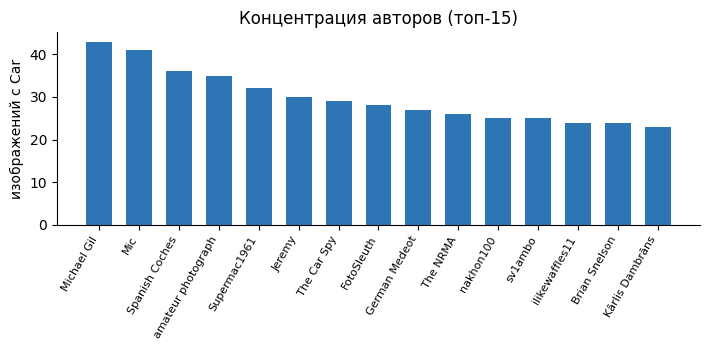

In [11]:
img_car = images[images.ImageID.isin(car.ImageID)].copy()
img_car["landing_domain"] = (img_car.OriginalLandingURL.fillna("")
                             .str.extract(r"https?://(?:www\.)?([^/]+)")[0])

lic = img_car.License.fillna("не указана").value_counts()
lic_table = pd.DataFrame({"изображений": lic, "доля, %": (lic / len(img_car) * 100).round(2)})
display(lic_table)
display(img_car.landing_domain.value_counts().rename("изображений").to_frame().head(5))

author_counts = img_car.Author.fillna("не указан").value_counts()
print(f"Уникальных авторов: {author_counts.size}")
print(f"Авторов с одной фотографией: {(author_counts == 1).sum()} "
      f"({(author_counts == 1).mean():.1%} авторов)")
print(f"Доля изображений у 10 самых активных авторов: "
      f"{author_counts.head(10).sum() / len(img_car):.1%}")
print("\nТоп-5 авторов:")
display(author_counts.head(5).rename("изображений").to_frame())

print(f"Отсутствует OriginalLandingURL: {img_car.OriginalLandingURL.isna().sum()}")
print(f"Отсутствует миниатюра для загрузки: {img_car.Thumbnail300KURL.isna().sum()} "
      f"({img_car.Thumbnail300KURL.isna().mean():.2%})")

license_author = pd.concat([
    lic_table.rename_axis("лицензия").reset_index().astype({"изображений": str}),
    pd.DataFrame([{"лицензия": "уникальных авторов", "изображений": str(author_counts.size)}]),
])
license_author.to_csv(TABLES / "cars_license_author.csv", index=False)

fig, ax = plt.subplots(figsize=(7.2, 3.6))
top = author_counts.head(15)
ax.bar(range(len(top)), top.values, color="#2E75B6", width=0.65)
ax.set_xticks(range(len(top)))
ax.set_xticklabels([a[:18] for a in top.index], rotation=60, ha="right", fontsize=8)
ax.set_ylabel("изображений с Car")
ax.set_title("Концентрация авторов (топ-15)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "15_cars_author_concentration.png", dpi=160)
plt.show()

## 8. План подвыборки и реестр изображений

Разбиение выполняется по авторам: все изображения одного автора попадают только в одну
часть. Алгоритм детерминирован (фиксированный `RANDOM_STATE`), поэтому оба участника
получают одинаковый реестр. Целевые объёмы: train 4 000, validation 500, test 500.

Дополнительно предусматривается слой отрицательных примеров: изображения раздела
validation без рамок Car. Без них precision детектора оценивается оптимистично,
поскольку модель никогда не видит кадр без объекта.

In [12]:
usable = img_car[img_car.Thumbnail300KURL.notna()].copy()
usable["n_boxes"] = usable.ImageID.map(per_image)

targets = {"train": 4000, "validation": 500, "test": 500}
rng = np.random.default_rng(RANDOM_STATE)

author_size = usable.Author.fillna("не указан").value_counts()
# перемешивание выполняется по копии: to_numpy() для индекса может вернуть
# представление, и shuffle испортил бы соответствие «автор — число изображений»
authors = (pd.DataFrame({"author": author_size.index.to_numpy().copy(),
                         "n": author_size.to_numpy()})
           .sample(frac=1.0, random_state=RANDOM_STATE)
           .sort_values("n", ascending=False, kind="stable")
           .reset_index(drop=True))

capacity = dict(targets)
author_split = {}
for a, n in zip(authors["author"], authors["n"]):
    n = int(n)
    fits = [k for k in targets if capacity[k] - n >= 0]
    if fits:
        k = max(fits, key=lambda s: (capacity[s] - n, -targets[s]))
    else:
        k = max(targets, key=lambda s: capacity[s])
    author_split[a] = k
    capacity[k] -= n

usable["split"] = usable.Author.fillna("не указан").map(author_split)

plan = (usable.groupby("split")
        .agg(изображений=("ImageID", "size"),
             авторов=("Author", "nunique"),
             рамок=("n_boxes", "sum"),
             медиана_рамок_на_изображение=("n_boxes", "median"))
        .reindex(["train", "validation", "test"]))
plan["цель, изображений"] = pd.Series(targets)
plan["доля от подвыборки, %"] = (plan["изображений"] / plan["изображений"].sum() * 100).round(1)
display(plan)
plan.to_csv(TABLES / "cars_subset_plan.csv")

overlap = (usable.groupby("Author").split.nunique() > 1).sum()
print(f"Авторов, чьи изображения попали в разные части: {overlap} "
      f"(должно быть 0)")
print(f"Всего изображений в подвыборке: {len(usable)} из {len(img_car)} доступных")

# отрицательные примеры: изображения validation без рамок Car
negatives = images[~images.ImageID.isin(car.ImageID) & images.Thumbnail300KURL.notna()]
print(f"Изображений без Car, доступных для слоя отрицательных примеров: {len(negatives)}")

,изображений,авторов,рамок,медиана_рамок_на_изображение,"цель, изображений","доля от подвыборки, %"
split,,,,,,
train,3998,1417,7918,1.0,4000,80.0
validation,499,499,902,1.0,500,10.0
test,499,499,941,1.0,500,10.0


Авторов, чьи изображения попали в разные части: 0 (должно быть 0)
Всего изображений в подвыборке: 4996 из 5095 доступных
Изображений без Car, доступных для слоя отрицательных примеров: 35104


In [13]:
manifest_cols = ["ImageID", "split", "n_boxes", "Author", "License",
                 "OriginalURL", "OriginalLandingURL", "Thumbnail300KURL"]
manifest = usable[manifest_cols].rename(columns={
    "ImageID": "image_id", "n_boxes": "n_car_boxes", "Author": "author",
    "License": "license", "OriginalURL": "original_url",
    "OriginalLandingURL": "landing_url", "Thumbnail300KURL": "thumbnail_url"})
manifest["source_split"] = "validation"
manifest["license_note"] = "CC BY 2.0, атрибуция по схеме TASL"
manifest["access_date"] = ACCESS_DATE
manifest = manifest.sort_values(["split", "image_id"]).reset_index(drop=True)

out_path = MANIFESTS / "cars_val_manifest.csv"
manifest.to_csv(out_path, index=False)
print(f"Реестр сохранён: {out_path.relative_to(ROOT)}  ({len(manifest)} строк)")
display(manifest.head(3))
print("\nКонтроль: пропуски в ключевых полях")
display(manifest[["image_id", "author", "license", "landing_url"]].isna().sum().to_frame("пропусков"))

Реестр сохранён: reports/manifests/cars_val_manifest.csv  (4996 строк)


,image_id,split,n_car_boxes,author,license,original_url,landing_url,thumbnail_url,source_split,license_note,access_date
0,00723dac8201a83e,test,4,Cirofono,https://creativecommons.org/licenses/by/2.0/,https://c7.staticflickr.com/1/150/432591931_9f...,https://www.flickr.com/photos/ciroduran/432591931,https://c2.staticflickr.com/1/150/432591931_47...,validation,"CC BY 2.0, атрибуция по схеме TASL",2026-10-22
1,020feca9b536f1fe,test,2,Connie,https://creativecommons.org/licenses/by/2.0/,https://c7.staticflickr.com/3/2059/2258982401_...,https://www.flickr.com/photos/conbon/2258982401,https://c1.staticflickr.com/3/2059/2258982401_...,validation,"CC BY 2.0, атрибуция по схеме TASL",2026-10-22
2,0403980601a6ee5b,test,1,Ellie Mills,https://creativecommons.org/licenses/by/2.0/,https://c4.staticflickr.com/8/7037/13279890365...,https://www.flickr.com/photos/120882277@N03/13...,https://c2.staticflickr.com/8/7037/13279890365...,validation,"CC BY 2.0, атрибуция по схеме TASL",2026-10-22



Контроль: пропуски в ключевых полях


,пропусков
image_id,0
author,0
license,0
landing_url,0


## 9. План пилотной разметки и оценка согласия

Согласие разметчиков оценивается на пилотной выборке до основной разметки. Если согласие ниже
порогов codebook (IoU ≥ 0,80 для рамок, доля совпавших решений ≥ 0,90), правила уточняются,
а пилот переразмечается.

Объём пилота определяется требуемой точностью оценки, а не удобством:

* для среднего IoU — `n = (z·σ/δ)²`, где σ — стандартное отклонение IoU в совокупности;
* для доли совпавших решений — `n = z²·p(1−p)/δ²`.

Величина σ заранее неизвестна, поэтому объём считается для трёх сценариев и берётся наибольший.
Выборка стратифицируется по признакам, которые задают трудность разметки: размер объекта,
перекрытие, обрезка. Пропорциональное размещение по стратам сохраняет структуру набора,
поэтому оценка согласия переносится на всю разметку.

,σ IoU (сценарий),объём для среднего IoU,"объём для доли совпадений (p = 0,90)","объём для доли совпадений (p = 0,80)"
0,0.05,4,139,246
1,0.10,16,139,246
2,0.15,35,139,246


Принятый объём пилота: 246 рамок (δ = 0,05, доверительная вероятность 95 %)


,доступно рамок,"доля, %",в пилоте,"доля от пилота, %"
stratum,,,,
"0,5–2 %|occ0|tr0",235,2.37,6,2.44
"0,5–2 %|occ0|tr1",301,3.03,7,2.85
"0,5–2 %|occ1|tr0",668,6.73,16,6.50
"0,5–2 %|occ1|tr1",265,2.67,7,2.85
2–5 %|occ0|tr0,111,1.12,3,1.22
2–5 %|occ0|tr1,251,2.53,6,2.44
2–5 %|occ1|tr0,400,4.03,10,4.07
2–5 %|occ1|tr1,330,3.33,8,3.25
5–15 %|occ0|tr0,131,1.32,3,1.22


Файл пилота: reports/manifests/cars_pilot_sample.csv (246 рамок)


,image_id,stratum,x_min,x_max,y_min,y_max,area_share,is_occluded,is_truncated,label_1,label_2,box_1,box_2,iou_12,annotator_1,annotator_2
0,0ca8141ebf85044e,"0,5–2 %|occ0|tr0",0.818750,0.992188,0.235417,0.327083,0.015898,0,0,,,,,,,
1,4dbc3c3022e7e4e0,"0,5–2 %|occ0|tr0",0.664212,0.751105,0.055310,0.119469,0.005575,0,0,,,,,,,
2,85ddb7e0f60156a3,"0,5–2 %|occ0|tr0",0.806499,0.892171,0.286976,0.384106,0.008321,0,0,,,,,,,


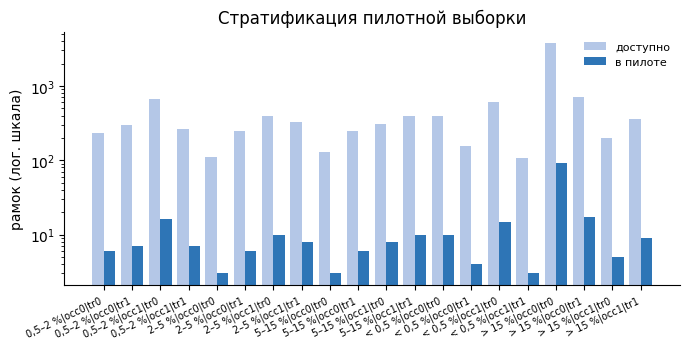

In [14]:
def n_for_mean(sigma: float, delta: float = 0.05, z: float = 1.96) -> int:
    return int(np.ceil((z * sigma / delta) ** 2))


def n_for_proportion(p: float, delta: float = 0.05, z: float = 1.96) -> int:
    return int(np.ceil(z ** 2 * p * (1 - p) / delta ** 2))


design = pd.DataFrame({"σ IoU (сценарий)": [0.05, 0.10, 0.15]})
design["объём для среднего IoU"] = [n_for_mean(s) for s in design["σ IoU (сценарий)"]]
design["объём для доли совпадений (p = 0,90)"] = n_for_proportion(0.90)
design["объём для доли совпадений (p = 0,80)"] = n_for_proportion(0.80)
display(design)
n_pilot = int(design[["объём для среднего IoU", "объём для доли совпадений (p = 0,90)",
                      "объём для доли совпадений (p = 0,80)"]].to_numpy().max())
print(f"Принятый объём пилота: {n_pilot} рамок (δ = 0,05, доверительная вероятность 95 %)")
design.to_csv(TABLES / "cars_pilot_design.csv", index=False)

SIZE_BINS = [0, 0.005, 0.02, 0.05, 0.15, 1.01]
SIZE_LABELS = ["< 0,5 %", "0,5–2 %", "2–5 %", "5–15 %", "> 15 %"]

strata = car.assign(size=pd.cut(car.area, bins=SIZE_BINS, labels=SIZE_LABELS, right=False))
strata["stratum"] = (strata["size"].astype(str)
                     + "|occ" + strata.IsOccluded.astype(int).astype(str)
                     + "|tr" + strata.IsTruncated.astype(int).astype(str))

available = strata.stratum.value_counts().sort_index()
exact = available / available.sum() * n_pilot
alloc = np.floor(exact).astype(int)
rest = int(n_pilot - alloc.sum())
if rest:
    alloc.loc[(exact - alloc).sort_values(ascending=False).index[:rest]] += 1

pilot_plan = pd.DataFrame({"доступно рамок": available,
                           "доля, %": (available / available.sum() * 100).round(2),
                           "в пилоте": alloc.clip(upper=available)})
pilot_plan["доля от пилота, %"] = (pilot_plan["в пилоте"] / pilot_plan["в пилоте"].sum() * 100).round(2)
display(pilot_plan)
pilot_plan.to_csv(TABLES / "cars_pilot_strata.csv")

parts = []
for stratum, group in strata.groupby("stratum"):
    take = int(min(pilot_plan.loc[stratum, "в пилоте"], len(group)))
    parts.append(group.sample(n=take, random_state=RANDOM_STATE))
sampled = pd.concat(parts).sort_values(["stratum", "ImageID"]).reset_index(drop=True)

pilot_sample = sampled[["ImageID", "stratum", "XMin", "XMax", "YMin", "YMax", "area",
                        "IsOccluded", "IsTruncated"]].rename(columns={
    "ImageID": "image_id", "area": "area_share", "IsOccluded": "is_occluded",
    "IsTruncated": "is_truncated", "XMin": "x_min", "XMax": "x_max",
    "YMin": "y_min", "YMax": "y_max"})
for col in ("label_1", "label_2", "box_1", "box_2", "iou_12"):
    pilot_sample[col] = ""
pilot_sample["annotator_1"] = ""
pilot_sample["annotator_2"] = ""
pilot_out = MANIFESTS / "cars_pilot_sample.csv"
pilot_sample.to_csv(pilot_out, index=False)
print(f"Файл пилота: {pilot_out.relative_to(ROOT)} ({len(pilot_sample)} рамок)")
display(pilot_sample.head(3))

fig, ax = plt.subplots(figsize=(7.0, 3.6))
x = np.arange(len(pilot_plan))
ax.bar(x - 0.2, pilot_plan["доступно рамок"], width=0.4, label="доступно", color="#B4C7E7")
ax.bar(x + 0.2, pilot_plan["в пилоте"], width=0.4, label="в пилоте", color="#2E75B6")
ax.set_xticks(x)
ax.set_xticklabels(pilot_plan.index, rotation=25, ha="right", fontsize=7)
ax.set_yscale("log")
ax.set_ylabel("рамок (лог. шкала)")
ax.set_title("Стратификация пилотной выборки")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "16_cars_pilot_strata.png", dpi=160)
plt.show()

## 10. Оценивание детекции: размерные группы и отрицательные примеры

Средняя точность по одному классу скрывает неравномерность по размеру объекта: мелких рамок
меньше, и согласие рамки при IoU 0,5 достигается для них труднее. Отсюда три требования к отчёту:

1. AP приводится отдельно по размерным группам; границы задаются по доле площади кадра,
   поскольку абсолютные пороги COCO неприменимы к изображениям разного разрешения;
2. для каждой группы указывается число рамок: при небольшом объёме доверительный интервал AP
   шире 0,05 и сравнение вариантов внутри такой группы не выполняется;
3. precision оценивается только при наличии отрицательных примеров. Если в тестовой части нет
   изображений без объекта, ложные срабатывания не учитываются и precision завышается.
   Число отрицательных изображений задаётся из целевой частоты ложных срабатываний
   по правилу трёх: при нуле срабатываний FPPI ≤ 3 / n с доверительной вероятностью 95 %.

Отдельно учитывается признак `IsGroupOf`: такая рамка обозначает группу объектов, а не один
объект, и не должна попадать в знаменатель при подсчёте числа объектов.

In [15]:
size_col = pd.cut(car.area, bins=SIZE_BINS, labels=SIZE_LABELS, right=False)
size_eval = size_col.value_counts().rename("рамок").to_frame()
size_eval["доля, %"] = (size_eval["рамок"] / len(car) * 100).round(2)
# полуширина интервала для доли при наихудшем случае p = 0,5
size_eval["полуширина 95 % ДИ для recall"] = (1.96 * np.sqrt(0.25 / size_eval["рамок"])).round(3)
size_eval["пригодна для сравнения вариантов"] = np.where(
    size_eval["полуширина 95 % ДИ для recall"] <= 0.05, "да", "нет: интервал шире 0,05")
display(size_eval.rename_axis("размерная группа"))
size_eval.to_csv(TABLES / "cars_size_eval.csv")

n_group_of = int(car.IsGroupOf.sum())
print(f"Рамок с IsGroupOf = 1: {n_group_of} ({n_group_of / len(car):.2%}); "
      f"исключаются из подсчёта числа объектов, остаются в оценке локализации")

neg_plan = pd.DataFrame({"целевая FPPI": [0.05, 0.02, 0.01]})
neg_plan["нужно изображений без объекта"] = np.ceil(3 / neg_plan["целевая FPPI"]).astype(int)
neg_plan["доступно в validation"] = len(negatives)
neg_plan["достаточно"] = np.where(neg_plan["нужно изображений без объекта"] <= len(negatives), "да", "нет")
display(neg_plan)
neg_plan.to_csv(TABLES / "cars_negatives_plan.csv", index=False)

required_images = int(neg_plan["нужно изображений без объекта"].max())
print(f"Для оценки FPPI с точностью до 0,01 нужно {required_images} изображений без объекта; "
      f"доступно {len(negatives)}")

,рамок,"доля, %",полуширина 95 % ДИ для recall,пригодна для сравнения вариантов
размерная группа,,,,
> 15 %,5027,50.65,0.014,да
"0,5–2 %",1469,14.80,0.026,да
"< 0,5 %",1257,12.67,0.028,да
2–5 %,1092,11.00,0.030,да
5–15 %,1079,10.87,0.030,да


Рамок с IsGroupOf = 1: 682 (6.87%); исключаются из подсчёта числа объектов, остаются в оценке локализации


,целевая FPPI,нужно изображений без объекта,доступно в validation,достаточно
0,0.05,60,35104,да
1,0.02,150,35104,да
2,0.01,300,35104,да


Для оценки FPPI с точностью до 0,01 нужно 300 изображений без объекта; доступно 35104


## 11. Эффективный объём выборки при разбиении по авторам

Изображения одного автора зависимы: это серии кадров одного объекта или одной сцены. При
разбиении по авторам модель не видит автора дважды, но оценка метрик всё равно содержит две
поправки:

* **эффективный объём выборки** — при неравномерном распределении изображений по авторам
  `N_eff = (Σn)² / Σn²`, где `n` — число изображений у автора. Неравномерность уменьшает
  информативность выборки: 4 000 изображений от 2 000 авторов информативнее, чем 4 000
  изображений, половина которых принадлежит одному автору;
* **коэффициент инфляции дисперсии** `deff = N / N_eff`: интервалы, построенные в предположении
  независимости объектов, занижаются в `√deff` раз. Поэтому интервалы для метрик детекции
  строятся кластерным бутстрэпом по изображениям (или по авторам), а не по рамкам.

In [16]:
def effective_sample(sizes) -> tuple[float, int]:
    s = np.asarray(sizes, dtype=float)
    return float(s.sum() ** 2 / (s ** 2).sum()), int(s.sum())


per_author_all = img_car.Author.fillna("не указан").value_counts()
ess_all, n_all = effective_sample(per_author_all)
rows = [{"выборка": "все изображения с Car", "изображений": n_all,
         "авторов": int(per_author_all.size), "эффективный объём": round(ess_all, 1),
         "deff": round(n_all / ess_all, 2), "инфляция интервала, раз": round(np.sqrt(n_all / ess_all), 2)}]

for split_name in ("train", "validation", "test"):
    part = usable[usable.split == split_name]
    sizes = part.Author.fillna("не указан").value_counts()
    ess_p, n_p = effective_sample(sizes)
    rows.append({"выборка": split_name, "изображений": n_p, "авторов": int(sizes.size),
                 "эффективный объём": round(ess_p, 1), "deff": round(n_p / ess_p, 2),
                 "инфляция интервала, раз": round(np.sqrt(n_p / ess_p), 2)})

ess_table = pd.DataFrame(rows)
display(ess_table)
ess_table.to_csv(TABLES / "cars_author_ess.csv", index=False)

top1 = per_author_all.iloc[0] / per_author_all.sum()
print(f"Доля изображений у самого крупного автора: {top1:.2%}")
print(f"Эффективный объём всей выборки: {ess_all:.0f} из {n_all} изображений "
      f"(инфляция интервала {np.sqrt(n_all / ess_all):.2f})")
print("Следствие: интервалы для mAP и FPPI строятся кластерным бутстрэпом по изображениям.")

,выборка,изображений,авторов,эффективный объём,deff,"инфляция интервала, раз"
0,все изображения с Car,5095,2468,697.4,7.31,2.70
1,train,3998,1417,447.5,8.93,2.99
2,validation,499,499,499.0,1.00,1.00
3,test,499,499,499.0,1.00,1.00


Доля изображений у самого крупного автора: 0.84%
Эффективный объём всей выборки: 697 из 5095 изображений (инфляция интервала 2.70)
Следствие: интервалы для mAP и FPPI строятся кластерным бутстрэпом по изображениям.


## 12. Регламент эксперимента и таблица результатов

| Элемент протокола | Значение |
|---|---|
| Данные | Open Images V7 validation, класс Car, SHA-256 из раздела 1 |
| Разбиение | по авторам, доли train / validation / test из раздела 8 |
| Основная метрика | mAP@0,5:0,95 (все точки) |
| Дополнительные метрики | AP@0,5, AP по размерным группам, FPPI на отрицательных изображениях |
| Порог уверенности | фиксируется на validation, на тесте не меняется |
| Интервалы | кластерный бутстрэп по изображениям, 500 повторов, 95 % |
| Число объектов | обязательно указывается рядом с каждой метрикой |
| Условие утверждения о превосходстве | интервал разности не содержит нуля, набор кадров и порог одинаковы |

Правила формулировок: запрещено сравнивать AP, полученные на разных наборах кадров, при разных
порогах уверенности и на разных реализациях интерполяции (11 точек против всех точек). Если
реализация интерполяции не указана, значение считается несопоставимым.

Варианты эксперимента: A — детектор на исходных данных; B — с ручной разметкой в обучении;
C — с ручной разметкой в обучении и в тесте (контроль утечки); D — с подбором порога по validation.

In [17]:
RESULT_COLUMNS = ["вариант", "метрика", "точечная оценка", "нижняя 95 %", "верхняя 95 %",
                  "объектов, шт.", "изображений, шт.", "порог уверенности", "random_state",
                  "дата", "примечание"]

results_template = pd.DataFrame(
    [{"вариант": v, "метрика": m} for v in ("A", "B", "C", "D")
     for m in ("mAP@0,5:0,95", "AP@0,5", "AP (< 2 % кадра)", "AP (> 15 % кадра)", "FPPI")],
    columns=RESULT_COLUMNS,
)
results_template.to_csv(TABLES / "cars_results_template.csv", index=False)
display(results_template.head(10))


def validate_results(table: pd.DataFrame) -> list[str]:
    problems = []
    missing = [c for c in RESULT_COLUMNS if c not in table.columns]
    if missing:
        return [f"нет колонок: {missing}"]
    filled = table.dropna(subset=["точечная оценка"])
    for _, r in filled.iterrows():
        if pd.isna(r["нижняя 95 %"]) or pd.isna(r["верхняя 95 %"]):
            problems.append(f"{r['вариант']} / {r['метрика']}: нет интервала")
        if pd.isna(r["объектов, шт."]):
            problems.append(f"{r['вариант']} / {r['метрика']}: не указано число объектов")
        if pd.isna(r["порог уверенности"]):
            problems.append(f"{r['вариант']} / {r['метрика']}: не указан порог уверенности")
    return problems


print("Пустая таблица: проблем не найдено" if not validate_results(results_template)
      else validate_results(results_template))

,вариант,метрика,точечная оценка,нижняя 95 %,верхняя 95 %,"объектов, шт.","изображений, шт.",порог уверенности,random_state,дата,примечание
0,A,"mAP@0,5:0,95",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,A,"AP@0,5",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,A,AP (< 2 % кадра),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,A,AP (> 15 % кадра),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,A,FPPI,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,B,"mAP@0,5:0,95",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,B,"AP@0,5",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,B,AP (< 2 % кадра),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,B,AP (> 15 % кадра),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,B,FPPI,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Пустая таблица: проблем не найдено


## 13. Сводка результатов

In [18]:
summary = pd.DataFrame(
    [
        ("Изображений с Car в validation", n_images),
        ("Рамок Car в validation", n_boxes),
        ("Рамок на изображение, среднее / медиана / максимум",
         f"{per_image.mean():.2f} / {int(per_image.median())} / {int(per_image.max())}"),
        ("Медианная площадь рамки, % кадра", round(car.area.median() * 100, 2)),
        ("Рамок меньше 0,5 % кадра, %", round((car.area < 0.005).mean() * 100, 2)),
        ("IsOccluded, % рамок", round(car.IsOccluded.mean() * 100, 2)),
        ("IsTruncated, % рамок", round(car.IsTruncated.mean() * 100, 2)),
        ("IsGroupOf, % рамок", round(car.IsGroupOf.mean() * 100, 2)),
        ("IsDepiction, % рамок", round(car.IsDepiction.mean() * 100, 2)),
        ("Рамок без атрибутов, %", round((car[attr_cols].sum(axis=1) == 0).mean() * 100, 2)),
        ("Лицензия изображений",
         f"{lic_table.index[0].replace('https://creativecommons.org/licenses/', 'CC ').replace('/', ' ').upper().strip()}"
         f" — {lic_table.iloc[0]['доля, %']}% изображений с Car"),
        ("Уникальных авторов", int(author_counts.size)),
        ("Доля изображений у топ-10 авторов, %", round(author_counts.head(10).sum() / len(img_car) * 100, 1)),
        ("Изображений в подвыборке (train / val / test)",
         f"{plan.loc['train', 'изображений']} / {plan.loc['validation', 'изображений']} / {plan.loc['test', 'изображений']}"),
        ("Объём пилота по согласию, рамок", n_pilot),
        ("Эффективный объём выборки (ESS)", f"{ess_all:.0f} из {n_all} (инфляция интервала {np.sqrt(n_all / ess_all):.2f})"),
        ("Рамок с IsGroupOf", n_group_of),
        ("Изображений без Car, нужно для FPPI 0,01", required_images),
        ("Изображений без миниатюры, %", round(img_car.Thumbnail300KURL.isna().mean() * 100, 2)),
    ],
    columns=["показатель", "значение"],
)
display(summary)
summary.to_csv(TABLES / "cars_eda_summary.csv", index=False)

print("\nСохранённые артефакты:")
for p in sorted(TABLES.glob("cars_*.csv")):
    print(" ", p.relative_to(ROOT))
for p in sorted(FIGURES.glob("1*_cars_*.png")):
    print(" ", p.relative_to(ROOT))
print(" ", out_path.relative_to(ROOT))

,показатель,значение
0,Изображений с Car в validation,5095
1,Рамок Car в validation,9924
2,"Рамок на изображение, среднее / медиана / макс...",1.95 / 1 / 43
3,"Медианная площадь рамки, % кадра",15.93
4,"Рамок меньше 0,5 % кадра, %",12.67
5,"IsOccluded, % рамок",36.46
6,"IsTruncated, % рамок",31.34
7,"IsGroupOf, % рамок",6.87
8,"IsDepiction, % рамок",1.03
9,"Рамок без атрибутов, %",41.34



Сохранённые артефакты:
  reports/tables/cars_annotation_stats.csv
  reports/tables/cars_attributes.csv
  reports/tables/cars_author_ess.csv
  reports/tables/cars_box_geometry.csv
  reports/tables/cars_dataset_passport.csv
  reports/tables/cars_eda_summary.csv
  reports/tables/cars_license_author.csv
  reports/tables/cars_negatives_plan.csv
  reports/tables/cars_pilot_design.csv
  reports/tables/cars_pilot_strata.csv
  reports/tables/cars_results_template.csv
  reports/tables/cars_size_eval.csv
  reports/tables/cars_subset_plan.csv
  reports/figures/11_cars_boxes_per_image.png
  reports/figures/12_cars_area_dist.png
  reports/figures/13_cars_attributes.png
  reports/figures/14_cars_position.png
  reports/figures/15_cars_author_concentration.png
  reports/figures/16_cars_pilot_strata.png
  reports/manifests/cars_val_manifest.csv


## 14. Выводы и следствия для дизайна эксперимента

1. Раздел validation содержит 5 095 изображений с классом Car и 9 924 рамки: требование
   ТЗ «не менее 3 000 экземпляров» выполняется, отдельная загрузка раздела train
   (около 1,2 ГБ аннотаций) не требуется.
2. Медианная площадь рамки — около 16 % кадра, но 12–13 % рамок меньше 0,5 % кадра,
   а медианное число объектов на изображение равно единице. Класс размеров объектов
   должен учитываться при расчёте AP по диапазонам площади и при выборе входного
   разрешения детектора (640 px достаточно для крупных объектов, мелкие требуют
   большего разрешения или тайлинга).
3. Доли `IsOccluded` ≈ 36 % и `IsTruncated` ≈ 31 % задают ожидаемую структуру ручного
   набора: если в собранных вручную данных эти доли близки к нулю, набор описывает
   другой домен, и это фиксируется в отчёте как сдвиг распределения, а не как дефект.
4. Политика «самого специфичного класса» подтверждена: подклассы (Van, Truck, Bus,
   Limousine и др.) размечены отдельно. Правило включается в codebook до начала
   пилотной разметки; иначе ручные рамки будут несопоставимы с исходными.
5. Все изображения с Car в проверенной части имеют лицензию CC BY 2.0 и заполненные
   поля автора и страницы-источника; 2 468 авторов, на топ-10 авторов приходится
   заметная доля кадров. Разбиение выполняется по авторам, иначе серия кадров одного
   фотографа попадает в train и test одновременно.
6. Подвыборка формируется детерминированно из доступных изображений (с миниатюрой):
   реестр `reports/manifests/cars_val_manifest.csv` содержит `image_id`, часть,
   автора, лицензию, исходный URL и дату обращения — этого достаточно для отчёта
   и для воспроизводимой повторной загрузки.
7. Согласие разметчиков оценивается на пилотной выборке объёмом, рассчитанным из требуемой
   точности (раздел 9), со стратификацией по размеру, перекрытию и обрезке. Порядок: пилот →
   расчёт IoU и доли совпадений → уточнение codebook → переразметка пилота.
8. Метрики детекции приводятся по размерным группам с указанием числа объектов; группы, где
   интервал шире 0,05, не используются для сравнения вариантов. Precision интерпретируется только
   при наличии отрицательных примеров, объём которых задаётся целевой FPPI (раздел 10).
9. Изображения одного автора зависимы: эффективный объём выборки меньше фактического, поэтому
   интервалы для mAP и FPPI строятся кластерным бутстрэпом по изображениям (раздел 11).
10. Подвыборка состоит только из кадров с машинами, поэтому в план включён слой
   отрицательных примеров (изображения validation без рамок Car). Без него precision
   детектора завышается.